# SHAP Waterfall (one prediction explained)

**Family:** Machine learning &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Machine learning:* Evaluate and explain fitted models: classification performance, calibration, learning curves, residuals, feature importance and feature effects.

## Design purpose

Explains a single prediction as a walk from the model's average output to this case's output. Each bar is one feature's contribution (its SHAP value), sorted by size, so the reader sees which facts about this applicant pushed the risk up and which pulled it down, and by how much.

## When to use

- Explain an individual decision to a customer, analyst or regulator (why was this loan declined?)
- Audit surprising predictions case by case
- Complement global importance charts with a concrete example

## Avoid when

- You need the model's overall behaviour (use a SHAP summary or permutation importance)
- Features are strongly correlated and the model is non-linear; attributions then depend on modelling choices and need care
- More than about ten features matter; fold the rest into one bar

## Alternatives

- SHAP summary (beeswarm) for the whole dataset
- SHAP dependence plot for one feature
- Reason codes table (the top 3–4 contributions in words)

## Design tips

- What it adds: global importance says what matters on average; the waterfall says what mattered for this one case, in the model's own units
- Start from the average prediction E[f(x)] and end at this case's f(x), and state both as probabilities as well as log-odds
- Label each bar with the feature's actual value (utilisation = 82%), not just its name
- Here the model is a logistic regression with independent features, so each contribution is exactly β·(x − mean): exact SHAP values in log-odds. Tree or neural models need the shap package

## Example

A simulated credit-default model (logistic regression on 8 applicant features, trained on 5,000 synthetic applicants), explaining one high-risk applicant.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.linear_model import LogisticRegression

### Data

In [2]:
rng = np.random.default_rng(5)
n = 5000
X = pd.DataFrame({
    "Credit utilisation (%)": rng.uniform(0, 100, n),
    "Debt-to-income (%)": rng.normal(30, 10, n).clip(0, 80),
    "Delinquencies (2 yrs)": rng.poisson(0.3, n),
    "Income ($k)": rng.lognormal(np.log(65), 0.4, n),
    "Account age (yrs)": rng.gamma(3, 3, n),
    "Credit inquiries (6 mo)": rng.poisson(1.2, n),
    "Loan amount ($k)": rng.lognormal(np.log(18), 0.5, n),
    "Employment (yrs)": rng.gamma(2, 3, n),
})
beta_true = np.array([0.035, 0.04, 0.6, -0.012, -0.08, 0.25, 0.012, -0.05])
logit = -3.0 + (X - X.mean()).to_numpy() @ beta_true
default = rng.binomial(1, 1 / (1 + np.exp(-logit)))
model = LogisticRegression(C=1e6, max_iter=5000).fit(X, default)

applicant = pd.Series({"Credit utilisation (%)": 82, "Debt-to-income (%)": 41, "Delinquencies (2 yrs)": 1,
                       "Income ($k)": 110, "Account age (yrs)": 3, "Credit inquiries (6 mo)": 4,
                       "Loan amount ($k)": 35, "Employment (yrs)": 14})
# Exact SHAP values for a linear model with independent features: beta_j * (x_j - E[x_j]), in log-odds.
shap = pd.Series(model.coef_[0] * (applicant - X.mean()).to_numpy(), index=X.columns)
base = model.intercept_[0] + model.coef_[0] @ X.mean().to_numpy()
pd.DataFrame({"value": applicant, "SHAP (log-odds)": shap.round(3)}).sort_values("SHAP (log-odds)")

,value,SHAP (log-odds)
Income ($k),110,-0.463
Employment (yrs),14,-0.383
Loan amount ($k),35,0.112
Debt-to-income (%),41,0.227
Delinquencies (2 yrs),1,0.378
Account age (yrs),3,0.394
Credit inquiries (6 mo),4,0.710
Credit utilisation (%),82,1.232


### Plot

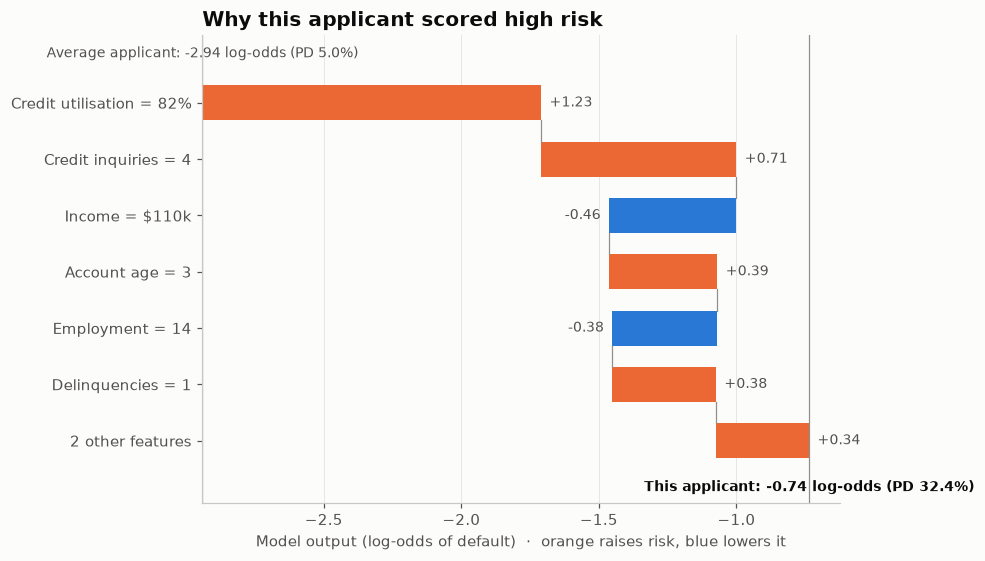

In [3]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
fmt = {"Credit utilisation (%)": "{:.0f}%", "Debt-to-income (%)": "{:.0f}%", "Income ($k)": "${:.0f}k",
       "Loan amount ($k)": "${:.0f}k"}
order = shap.abs().sort_values(ascending=False).index
top, rest = order[:6], order[6:]
rows = [(f"{f.split(' (')[0]} = {fmt.get(f, '{:g}').format(applicant[f])}", shap[f]) for f in top]
rows.append((f"{len(rest)} other features", shap[rest].sum()))

fig, ax = plt.subplots(figsize=(9, 5.2))
start = base
for i, (label, v) in enumerate(rows):
    color = PALETTE[1] if v > 0 else PALETTE[0]
    ax.barh(i, v, left=start, height=0.62, color=color)
    ax.text(start + v + (0.03 if v > 0 else -0.03), i, f"{v:+.2f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9, color="#52514e")
    if i < len(rows) - 1:
        ax.plot([start + v] * 2, [i + 0.31, i + 0.69], color="#8f8e88", linewidth=0.8)
    start += v
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.invert_yaxis()
for x in (base, start):
    ax.axvline(x, color="#8f8e88", linewidth=0.8)
ax.text(base, -0.75, f"Average applicant: {base:.2f} log-odds (PD {sigmoid(base):.1%})",
        ha="center", va="bottom", fontsize=9, color="#52514e")
ax.text(start, len(rows) - 0.3, f"This applicant: {start:.2f} log-odds (PD {sigmoid(start):.1%})",
        ha="center", va="top", fontsize=9, color="#0b0b0b", fontweight="bold")
ax.set_ylim(len(rows) + 0.1, -1.2)
ax.set_xlabel("Model output (log-odds of default)  ·  orange raises risk, blue lowers it")
ax.set_title("Why this applicant scored high risk")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## How to read it

The average applicant has a 5% default probability (top). High credit utilisation and four recent credit inquiries push this applicant's risk up the most, and a short account history and a past delinquency add more (orange). A high income and 14 years of employment pull it down (blue). The applicant ends at about a 32% default probability.

## Reference

This method comes from the research literature:

- Lundberg, S. M. et al. (2020). From local explanations to global understanding with explainable AI for trees. Nature Machine Intelligence 2, 56–67. <https://doi.org/10.1038/s42256-019-0138-9>

---
Standalone script: [`shap_waterfall.py`](shap_waterfall.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)